In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.data import load_data, clean_data, split_data
from src.features import build_preprocessor

df = clean_data(load_data("../data/telco_churn.csv"))
X_train, X_test, y_train, y_test = split_data(df)

ratio = (y_train == 0).sum() / (y_train == 1).sum()
model = Pipeline([
    ("prep", build_preprocessor(X_train)),
    ("clf", XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        scale_pos_weight=ratio, random_state=42, eval_metric="logloss",
    )),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print("Done:", oof_proba.shape)

Done: (5634,)


Best threshold: 0.34
Profit at best threshold: $ 101020
Profit at default 0.50:   $ 97700
Profit if we flag nobody: $ 0


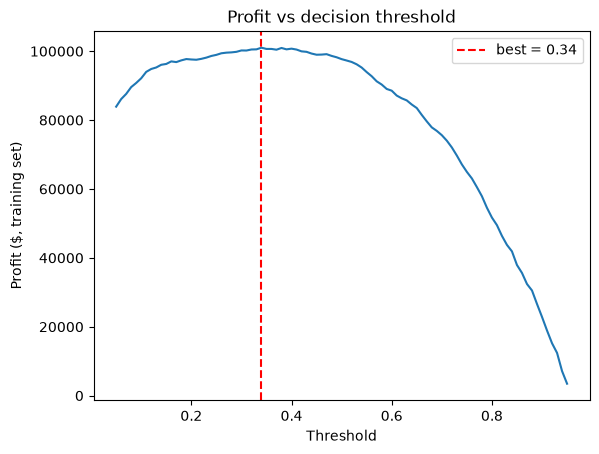

In [2]:
COST_OFFER = 20      # $ per retention offer sent
VALUE_SAVED = 400    # $ value of a customer we keep
SUCCESS_RATE = 0.30  # share of would-be churners an offer actually saves


def profit_at(proba, y_true, threshold):
    y = np.asarray(y_true)
    flagged = proba >= threshold
    n_flagged = flagged.sum()
    caught = (flagged & (y == 1)).sum()
    return caught * SUCCESS_RATE * VALUE_SAVED - n_flagged * COST_OFFER


thresholds = np.arange(0.05, 0.96, 0.01)
profits = [profit_at(oof_proba, y_train, t) for t in thresholds]

best_t = thresholds[int(np.argmax(profits))]
print("Best threshold:", round(best_t, 2))
print("Profit at best threshold: $", round(max(profits)))
print("Profit at default 0.50:   $", round(profit_at(oof_proba, y_train, 0.5)))
print("Profit if we flag nobody: $ 0")

plt.plot(thresholds, profits)
plt.axvline(best_t, linestyle="--", color="red", label=f"best = {best_t:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Profit ($, training set)")
plt.title("Profit vs decision threshold")
plt.legend()
plt.show()

In [3]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score

model.fit(X_train, y_train)
test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_t).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print("Recall:   ", round(recall_score(y_test, test_pred), 3))
print("Precision:", round(precision_score(y_test, test_pred), 3))
print("Confusion matrix [[TN FP] [FN TP]]:")
print(confusion_matrix(y_test, test_pred))

print("\nTest profit at chosen threshold: $", round(profit_at(test_proba, y_test, best_t)))
print("Test profit at default 0.50:     $", round(profit_at(test_proba, y_test, 0.5)))
print("Test profit, flag everyone:      $", round(profit_at(test_proba, y_test, 0.0)))

Test ROC-AUC: 0.842
Recall:    0.882
Precision: 0.457
Confusion matrix [[TN FP] [FN TP]]:
[[643 392]
 [ 44 330]]

Test profit at chosen threshold: $ 25160
Test profit at default 0.50:     $ 23800
Test profit, flag everyone:      $ 16700
